<center>
<h1><b> TP3: Prompt Engineering </b>
<h1><b>Classification tasks : Sentiment Analysis </b>
</center>

### 1. Import Libraries

In [31]:
from langchain_ollama import ChatOllama
from IPython.display import display, Markdown
import pandas as pd
import json
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import os
from dotenv import load_dotenv

In [32]:
load_dotenv()

True

### 2. Load the IMDB Dataset

Load the IMDB movie review dataset using Hugging Face Datasets. Each review is associated with a label indicating whether its sentiment is positive or negative.

In [33]:
from datasets import load_dataset

# load IMDB dataset
dataset = load_dataset("stanfordnlp/imdb")

In [34]:
# Convert the  dataset into a pandas DataFrame
df = dataset["train"].to_pandas()

### 3. Explore the dataset

In [35]:
# Display some random rows
df.sample(10)

,text,label
11248,DarkWolf tells the tale of a young waitress na...,0
9461,There is a key aspect of film that Jobson seem...,0
2888,I rented this horrible movie. The worst think ...,0
16648,I ran across this several years ago while chan...,1
7170,Aaron Spelling produced this made for televisi...,0
6986,This was the worst MTV Movie Awards EVER!!! I ...,0
16772,This is an excellent movie with a stellar cast...,1
11804,"Mmm, doesn't a big stack of pancakes sound goo...",0
17796,As a knowledgeable fan I recommend this film a...,1
384,I was one of quite a few extras in this big bo...,0


In [36]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    25000 non-null  str  
 1   label   25000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 32.0 MB


In [37]:
# Display column names
df.columns

Index(['text', 'label'], dtype='str')

In [38]:
# Number of rows and columns
df.shape

(25000, 2)

In [39]:
# Display column data types
df.dtypes

text       str
label    int64
dtype: object

In [40]:
# Count missing values in each column
df.isnull().sum()


text     0
label    0
dtype: int64

In [41]:
# Count duplicated rows
print(df.duplicated().sum())

96


In [42]:
# Count occurrences of each label
df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [43]:
# Add a textual sentiment label based on the numerical label
df["sentiment"] = df["label"].map({
    1: "positive",
    0:"negative"
})

# check the result
df.sample(10)

,text,label,sentiment
14410,I saw this film when it was originally release...,1,positive
2581,"honestly, if anyone has a brain, there's not 1...",0,negative
10429,Did I step in something or is that bad smell c...,0,negative
5308,"Kol, space prisoner on space death row, manage...",0,negative
16682,Lawrence Olivier and Merle Oberon did two movi...,1,positive
16823,this film takes you inside itself in the early...,1,positive
4839,This reworking of Anthony Shaffer's classic pl...,0,negative
23579,"""I'll Take You There"" tells of a woebegone man...",1,positive
8000,this by far one of the worst movies I have eve...,0,negative
18897,i went to see this movie with a bunch of frien...,1,positive


<Axes: >

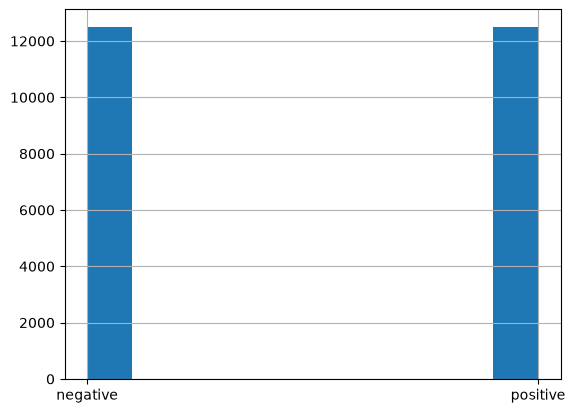

In [44]:
# check uding a histogram
df["sentiment"].hist()

## 4. Split the dataset into two pools

We divide the dataset into two pools: 80% for selecting few-shot examples to construct prompts and 20% for gold examples to evaluate the LLM's predictions.

In [45]:
# split df
examples_df, gold_examples_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

# Check the dimensions of both datasets
examples_df.shape, gold_examples_df.shape

((20000, 3), (5000, 3))

In [46]:
# Save the datases as JSON files

# Save the few-shot examples pool
examples_df.to_json("examples.json", orient="records", indent=2)

# Save the gold examples pool
gold_examples_df.to_json("gold_examples.json", orient="records", indent=2)


gold_examples = gold_examples_df.to_json(orient="records")


In [47]:
# Convert the DataFrame to JSON
examples = examples_df.to_json(orient="records")

# Load the JSON string into a Python list
json.loads(examples)[1]

{'text': "After the unexpected accident that killed an inexperienced climber (Michelle Joyner). Eight months has passed... The Rocky Mountain Rescue receive a distress call set by a brilliant terrorist mastermind Eric Quaien (John Lithgow). Quaien has lost three large cases that has millions of dollars inside. Two experienced climbers Walker (Sylvester Stallone) and Tucker (Micheal Rooker) and a helicopter pilot (Janine Turner) are to the rescue but they are set by a trap by Quaien and his men. Now the two climbers and pilot are forced to play a deadly game of hide and seek. While Quaien is trying to find the millions of dollars and he kidnapped Tucker to find the money. Once Tucker finds the money, Tucker will be dead. Against explosive firepower, bitter cold and dizzying heights. Walker must outwit Quaien for survival.<br /><br />Directed by Renny Harlin (Driven, Mindhunters, A Nightmare on Elm Street 4:The Dream Master) made an entertaining non-stop action picture. This film is a sp

### 6. Create the few-shot examples

We select 4 positive and 4 negative reviews from examples_df to provide the LLM with examples of each sentiment.

In [48]:
# Select positive and negative reviews
positive_reviews = examples_df.sentiment == "positive"
negative_reviews = examples_df.sentiment == "negative"

# Select the required columns
columns = ["text", "sentiment"]

# Randomly sample 4 examples from each sentiment
positive_examples = examples_df.loc[positive_reviews, columns].sample(4)
negative_examples = examples_df.loc[negative_reviews, columns].sample(4)

# Combine the examples into one DataFrame
examples = pd.concat([positive_examples, negative_examples])

# Shuffle the 8 examples and convert them to JSON
examples = examples.sample(8, replace=False).to_json(orient="records")

# Display the examples
json.loads(examples)

[{'text': "Yes, it's flawed - especially if you're into Hollywood films that demand a lot of effects, a purely entertaining or fantasy story or plot, and you can't actually think for yourself.<br /><br />Roeg's films are for the intelligent film-goer, and Insignificance is a perfect example.<br /><br />The characterizations are brilliant, the story is excellent, but, like all Nic Roeg's films - it has you thinking on every level about aspects of reality that would never have dawned on you before. His films always make you think, and personally, I like that in a film.<br /><br />So don't expect to come away from watching this film and feeling all happy-happy, because it's likely you'll be disappointed.<br /><br />But I think it's excellent.",
  'sentiment': 'positive'},
 {'text': 'This slick and gritty film consistently delivers. It\'s one of Frankenheimer\'s best and most underrated films and it\'s easily the best Elmore Leonard adaptation to date (and if you are scratching your head t

### 7. Define the function to create few-shot examples

We create a reusable function that randomly selects n positive and n negative reviews from a dataset and returns them as a JSON string.

In [49]:
# Create a function to select balanced few-shot examples
def create_examples(dataset, n=4):
    positive_reviews = dataset.sentiment == "positive"
    negative_reviews = dataset.sentiment == "negative"

    columns_to_select = ["text", "sentiment"]

    positive_examples = dataset.loc[
        positive_reviews, columns_to_select
    ].sample(n)

    negative_examples = dataset.loc[
        negative_reviews, columns_to_select
    ].sample(n)

    examples = pd.concat([positive_examples, negative_examples])

    # Shuffle the examples and convert them to JSON
    randomized_examples = examples.sample(2 * n, replace=False)

    return randomized_examples.to_json(orient="records")

### 8. Define the system message

We define the instructions that tell the LLM to classify movie reviews as positive or negative and return only the sentiment without explanation.

In [50]:
# Define the system message for few-shot classification

few_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as
'positive' or 'negative'.
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'.
Do not explain your answer.
"""

### 9. Define the user message template

We define the format of the message containing the movie review that the LLM must classify.

In [51]:
# Define the template for a movie review
user_message_template = """
Classify the sentiment of the following movie review:
```{movie_review}```
"""

zero_shot_system_message = """
Classify the sentiment of movie reviews presented in the input as
'positive' or 'negative'.
Movie reviews will be delimited by triple backticks in the input.
Answer only 'positive' or 'negative'.
Do not explain your answer.
"""

zero_shot_prompt = [
    {"role": "system", "content": zero_shot_system_message}
]

### 10. Create the few-shot prompt

We create a function that combines the system instructions with the eight labeled examples, allowing the LLM to use them as context when classifying new reviews.

In [52]:
# Create a few-shot prompt from the instructions and examples
def create_prompt(system_message, examples, user_message_template):
    few_shot_prompt = [
        {
            "role": "system",
            "content": system_message
        }
    ]

    for example in json.loads(examples):
        example_review = example["text"]
        example_sentiment = example["sentiment"]

        few_shot_prompt.append({
            "role": "user",
            "content": user_message_template.format(
                movie_review=example_review
            )
        })

        few_shot_prompt.append({
            "role": "assistant",
            "content": example_sentiment
        })

    return few_shot_prompt

### 11. Assemble the few-shot prompt
We use create_examples() to select 8 examples, then create_prompt() to combine them with the system instructions and user message template.

In [53]:
# Select 4 positive and 4 negative examples
examples = create_examples(examples_df)

# Assemble the few-shot prompt
few_shot_prompt = create_prompt(
    few_shot_system_message,
    examples,
    user_message_template
)

# Display the prompt
few_shot_prompt

[{'role': 'system',
  'content': "\nClassify the sentiment of movie reviews presented in the input as\n'positive' or 'negative'.\nMovie reviews will be delimited by triple backticks in the input.\nAnswer only 'positive' or 'negative'.\nDo not explain your answer.\n"},
 {'role': 'user',
  'content': "\nClassify the sentiment of the following movie review:\n```The way the story is developed, keeps the audience wondering what is the tenant's dark past. We get some clues during the series, but enough to keep us interested in the mini-series. The characters are all believable and I personally felt immersed and surrounded by the story.```\n"},
 {'role': 'assistant', 'content': 'positive'},
 {'role': 'user',
  'content': "\nClassify the sentiment of the following movie review:\n```They made me watch this in school and it was terrible. The movie is outdated. The episodes become confusing because fact is combined with fiction to make the story more interesting.The teachers talked about it as a 

### 12. Define the Chain-of-Thought prompt
We add step-by-step reasoning instructions to the system message to compare this approach with the standard few-shot prompt.

In [54]:
# Define the Chain-of-Thought system message
cot_system_message = """
Classify the sentiment of movie reviews presented in the input
as 'positive' or 'negative'.
Movie reviews will be delimited by triple backticks ``` in the
input.
Answer only 'positive' or 'negative'
Do not explain your answer.

Instructions:
1. Carefully read the text of the review and think through the
   options for sentiment provided
2. Consider the overall sentiment of the review and estimate
   the probability of the review being positive

To reiterate, your answer should strictly only contain the
label: positive or negative
"""

### 13. Assemble the CoT prompt
We combine the CoT system message with the same few-shot examples and user message template to create the prompt used for Chain-of-Thought evaluation.

In [55]:
# Assemble the Chain-of-Thought prompt
cot_few_shot_prompt = create_prompt(
    cot_system_message,
    examples,
    user_message_template
)

### 14. Define the evaluation function
We create a function that sends each gold review to the LLM, collects its predicted sentiment, and calculates the micro-F1 score by comparing predictions with the true labels.

In [56]:
# Evaluate a prompt using the gold examples
def evaluate_prompt(prompt, gold_examples, user_message_template, model):
    model_predictions, ground_truths = [], []

    for example in json.loads(gold_examples)[:100]:
        user_input = [{
            "role": "user",
            "content": user_message_template.format(
                movie_review=example["text"]
            )
        }]

        try:
            response = model.chat(
                model="gpt-oss:120b",
                messages=prompt + user_input
            )

            answer = response["message"]["content"].strip().lower()

            if answer == "positive":
                prediction = "positive"
            elif answer == "negative":
                prediction = "negative"
            else:
                prediction = "unknown"

            model_predictions.append(prediction)
            ground_truths.append(example["sentiment"])

        except Exception as e:
            print(f"Erreur : {e}")

    if not ground_truths:
        return 0.0

    return f1_score(
        ground_truths,
        model_predictions,
        average="micro"
    )

### 15. Initialize the Ollama model
We initialize a local LLM using Ollama instead of GPT-5.2, avoiding API costs.

In [57]:
api_key = os.getenv("OLLAMA_API_KEY")
assert api_key, "OLLAMA_API_KEY not found"

llm = ChatOllama(
    model="gpt-oss:120b",
    base_url="https://ollama.com",
    client_kwargs={
        "headers": {
            "Authorization": f"Bearer {api_key}"
        }
    },
    temperature=0
)

## Testing

In [58]:
from ollama import Client

client = Client(
    host="https://ollama.com",
    headers={
        "Authorization": f"Bearer {os.getenv('OLLAMA_API_KEY')}"
    }
)

In [59]:
response = client.chat(
    model="gpt-oss:120b",
    messages=[
        {"role": "user", "content": "Reply only: positive"}
    ]
)

print(response["message"]["content"])

Absolutely!


In [60]:
# Evaluate the Zero-shot prompt

zero_shot_score = evaluate_prompt(
    zero_shot_prompt,
    gold_examples,
    user_message_template,
    client
)

# Evaluate the Few-shot prompt
few_shot_score = evaluate_prompt(
    few_shot_prompt,
    gold_examples,
    user_message_template,
    client
)

# Evaluate the CoT prompt
cot_score = evaluate_prompt(
    cot_few_shot_prompt,
    gold_examples,
    user_message_template,
    client
)

# Display the results
print("Zero-shot micro-F1:", zero_shot_score)
print("Few-shot micro-F1:", few_shot_score)
print("CoT micro-F1:", cot_score)

Erreur : Server disconnected without sending a response.
Zero-shot micro-F1: 0.95
Few-shot micro-F1: 0.96
CoT micro-F1: 0.9292929292929293
